In [1]:
# Import libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("../data/ai4i2020.csv")

# Display the first five rows
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [2]:
# Inspect the dataset structure
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (10000, 14)

Column names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-

In [3]:
# Generate descriptive statistics for numerical columns
df.describe().round(2)

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00,10000.0,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,5000.50,300.0,310.01,1538.78,39.99,107.95,0.03,0.00,0.01,0.01,0.01,0.00
std,2886.90,2.0,1.48,179.28,9.97,63.65,0.18,0.07,0.11,0.10,0.10,0.04
min,1.00,295.3,305.70,1168.00,3.80,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,2500.75,298.3,308.80,1423.00,33.20,53.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,5000.50,300.1,310.10,1503.00,40.10,108.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,7500.25,301.5,311.10,1612.00,46.80,162.00,0.00,0.00,0.00,0.00,0.00,0.00
max,10000.00,304.5,313.80,2886.00,76.60,253.00,1.00,1.00,1.00,1.00,1.00,1.00


In [4]:
# Count machine failures and calculate their proportions
failure_counts = df["Machine failure"].value_counts().sort_index()
failure_percentages = df["Machine failure"].value_counts(normalize=True).sort_index() * 100

failure_summary = pd.DataFrame({
    "Count": failure_counts,
    "Percentage": failure_percentages.round(2)
})

failure_summary.index = ["No Failure", "Failure"]
failure_summary

,Count,Percentage
No Failure,9661,96.61
Failure,339,3.39


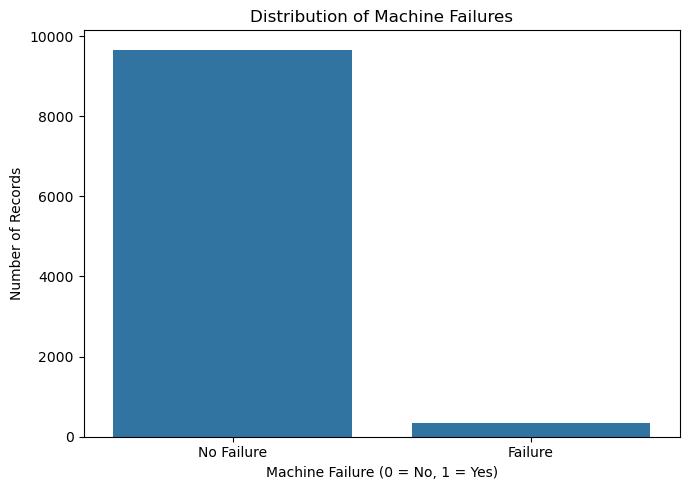

In [5]:
# Visualize the distribution of machine failures
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Machine failure")

plt.title("Distribution of Machine Failures")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")
plt.xticks([0, 1], ["No Failure", "Failure"])
plt.tight_layout()
plt.show()

In [6]:
# Compare operating conditions for machines with and without failure
features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

df.groupby("Machine failure")[features].mean().T.round(2)

Machine failure,0,1
Air temperature [K],299.97,300.89
Process temperature [K],310.00,310.29
Rotational speed [rpm],1540.26,1496.49
Torque [Nm],39.63,50.17
Tool wear [min],106.69,143.78


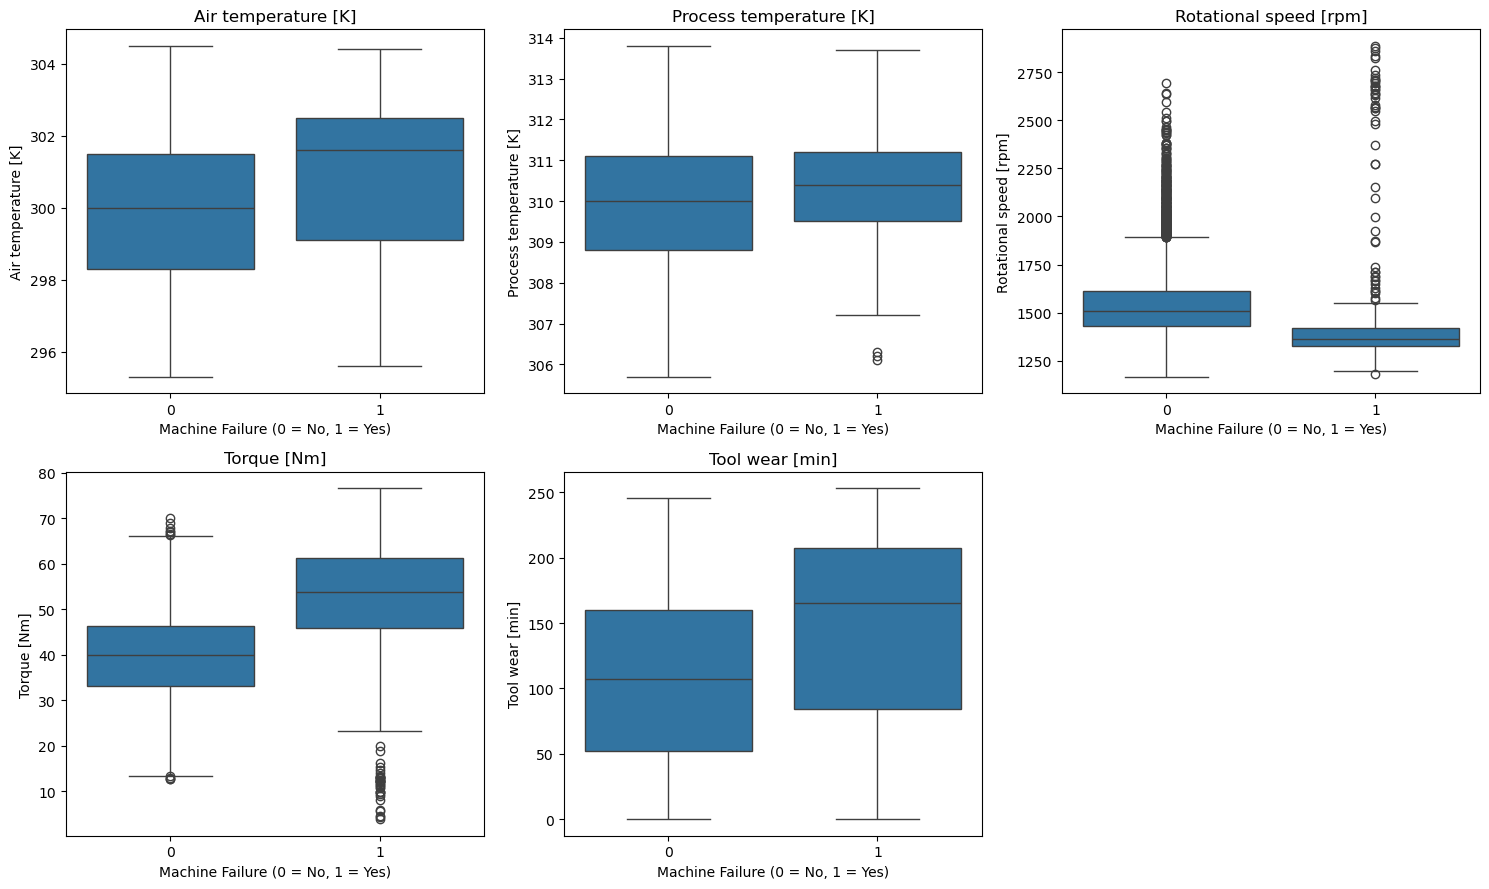

In [7]:
# Compare feature distributions across failure classes
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, feature in enumerate(features):
    sns.boxplot(
        data=df,
        x="Machine failure",
        y=feature,
        ax=axes[i]
    )
    axes[i].set_title(feature)
    axes[i].set_xlabel("Machine Failure (0 = No, 1 = Yes)")

# Remove the unused subplot
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

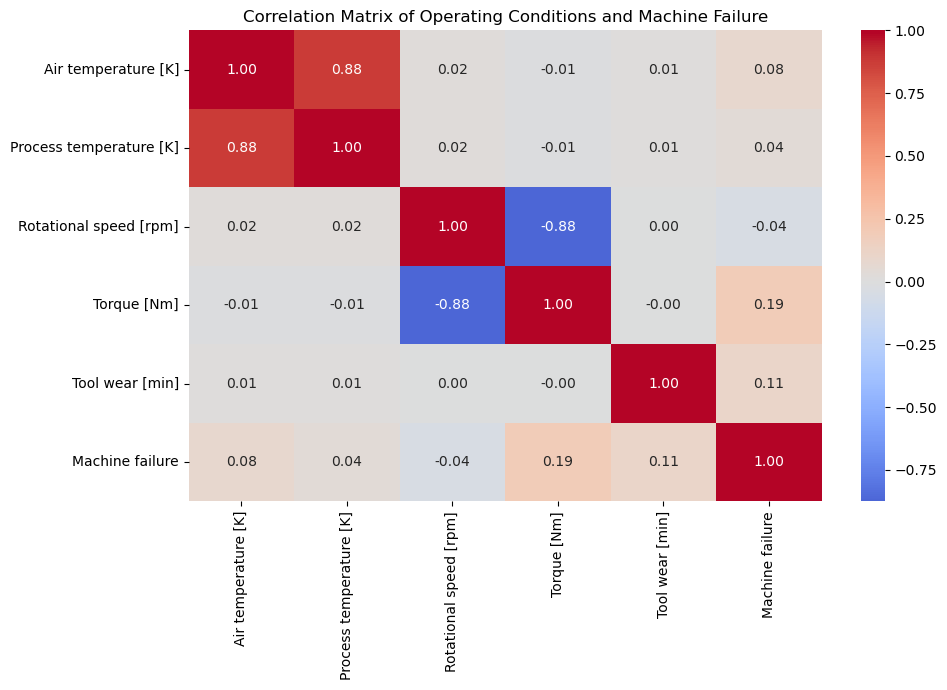

In [8]:
# Calculate correlations between numerical features
correlation_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Machine failure"
]

correlation_matrix = df[correlation_features].corr()

# Visualize the correlation matrix
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Operating Conditions and Machine Failure")
plt.tight_layout()
plt.show()

In [9]:
# Compare machine failure rates across product types
failure_by_type = df.groupby("Type")["Machine failure"].agg(
    Total_Records="count",
    Failures="sum",
    Failure_Rate="mean"
)

failure_by_type["Failure_Rate"] = (
    failure_by_type["Failure_Rate"] * 100
).round(2)

print("Failure Statistics by Product Type:")
print(failure_by_type.to_string())

# Compare failure rates across product types and machine failure status
print("\nFailure Counts by Product Type:")
print(
    pd.crosstab(
        df["Type"],
        df["Machine failure"],
        margins=True
    ).to_string()
)

Failure Statistics by Product Type:
      Total_Records  Failures  Failure_Rate
Type                                       
H              1003        21          2.09
L              6000       235          3.92
M              2997        83          2.77

Failure Counts by Product Type:
Machine failure     0    1    All
Type                             
H                 982   21   1003
L                5765  235   6000
M                2914   83   2997
All              9661  339  10000
